# LSTM Model Development & Training

In this notebook, I'll use historical retail sales data to build a model that can forecast future sales.

I'll start by loading the daily sales data prepared in the previous notebook. Then I'll create a simple baseline forecast, prepare sequential data, and build an LSTM model to compare its performance against that baseline.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
class SalesDataLoader:
    def __init__(self, file_path):
        self.file_path = Path(file_path)

    def load_data(self):
        if not self.file_path.exists():
            raise FileNotFoundError(
                f"Could not find the dataset: {self.file_path}"
            )

        df = pd.read_csv(self.file_path, parse_dates=["date"])
        return df

In [3]:
data_path = Path("../outputs/processed/daily_sales.csv")

loader = SalesDataLoader(data_path)
sales_df = loader.load_data()

sales_df.head()

,date,daily_sales
0,2013-01-01,2511.618999
1,2013-01-02,496092.417944
2,2013-01-03,361461.231124
3,2013-01-04,354459.677093
4,2013-01-05,477350.121229


In [4]:
print("Dataset shape:", sales_df.shape)
print("\nColumn names:")
print(sales_df.columns.tolist())

print("\nData types:")
print(sales_df.dtypes)

print("\nDate range:")
print(sales_df["date"].min(), "to", sales_df["date"].max())

print("\nMissing values:")
print(sales_df.isnull().sum())

print("\nDuplicate dates:", sales_df["date"].duplicated().sum())

Dataset shape: (1688, 2)

Column names:
['date', 'daily_sales']

Data types:
date           datetime64[ns]
daily_sales           float64
dtype: object

Date range:
2013-01-01 00:00:00 to 2017-08-15 00:00:00

Missing values:
date           0
daily_sales    0
dtype: int64

Duplicate dates: 0


## Baseline Forecast

Before training an LSTM model, I'll establish a simple baseline. The baseline assumes that the next day's sales will be the same as the current day's sales.

This gives me a reference point for evaluating whether the LSTM can make more accurate predictions.

In [5]:
class TimeSeriesSplitter:
    def __init__(self, test_size=0.2):
        self.test_size = test_size

    def split(self, df):
        split_index = int(len(df) * (1 - self.test_size))

        train = df.iloc[:split_index].copy()
        test = df.iloc[split_index:].copy()

        return train, test

In [6]:
splitter = TimeSeriesSplitter(test_size=0.2)

train_df, test_df = splitter.split(sales_df)

print("Training rows:", len(train_df))
print("Testing rows:", len(test_df))

print("\nTraining period:")
print(train_df["date"].min(), "to", train_df["date"].max())

print("\nTesting period:")
print(test_df["date"].min(), "to", test_df["date"].max())

Training rows: 1350
Testing rows: 338

Training period:
2013-01-01 00:00:00 to 2016-09-11 00:00:00

Testing period:
2016-09-12 00:00:00 to 2017-08-15 00:00:00


In [7]:
class NaiveForecaster:
    def predict(self, train_df, test_df):
        last_train_sales = train_df["daily_sales"].iloc[-1]

        predictions = [last_train_sales]

        for i in range(1, len(test_df)):
            predictions.append(
                test_df["daily_sales"].iloc[i - 1]
            )

        return np.array(predictions)

In [8]:
baseline_model = NaiveForecaster()

baseline_predictions = baseline_model.predict(
    train_df,
    test_df
)

print("Number of predictions:", len(baseline_predictions))
print("Number of test observations:", len(test_df))
print("\nFirst five predictions:")
print(baseline_predictions[:5])

Number of predictions: 338
Number of test observations: 338

First five predictions:
[1017369.2242663  678776.4591265  603427.946974   624262.071976
  568324.812986 ]


## Sequential Data Preparation

An LSTM needs input data arranged into sequences. For this project, I'll use the previous 30 days of sales to predict sales for the following day.

I'll scale the sales values before training because neural networks generally train more effectively when input values are on a manageable scale. The scaler will be fitted only on the training data to avoid information leaking from future observations.

In [9]:
from sklearn.preprocessing import MinMaxScaler

In [10]:
class SequencePreprocessor:
    def __init__(self, lookback=30):
        self.lookback = lookback
        self.scaler = MinMaxScaler()

    def fit_scaler(self, train_values):
        self.scaler.fit(train_values.reshape(-1, 1))

    def transform(self, values):
        return self.scaler.transform(
            values.reshape(-1, 1)
        )

    def create_sequences(self, values):
        X = []
        y = []

        for i in range(self.lookback, len(values)):
            X.append(values[i - self.lookback:i, 0])
            y.append(values[i, 0])

        return np.array(X), np.array(y)

In [11]:
validation_size = int(len(train_df) * 0.2)

model_train_df = train_df.iloc[:-validation_size].copy()
validation_df = train_df.iloc[-validation_size:].copy()

print("Model training rows:", len(model_train_df))
print("Validation rows:", len(validation_df))
print("Final test rows:", len(test_df))

print("\nModel training period:")
print(model_train_df["date"].min(), "to", model_train_df["date"].max())

print("\nValidation period:")
print(validation_df["date"].min(), "to", validation_df["date"].max())

print("\nFinal test period:")
print(test_df["date"].min(), "to", test_df["date"].max())

Model training rows: 1080
Validation rows: 270
Final test rows: 338

Model training period:
2013-01-01 00:00:00 to 2015-12-16 00:00:00

Validation period:
2015-12-17 00:00:00 to 2016-09-11 00:00:00

Final test period:
2016-09-12 00:00:00 to 2017-08-15 00:00:00


In [12]:
sequence_preprocessor = SequencePreprocessor(lookback=30)

train_values = model_train_df["daily_sales"].to_numpy()

sequence_preprocessor.fit_scaler(train_values)

print("Scaler fitted on training data.")
print("Lookback window:", sequence_preprocessor.lookback, "days")

Scaler fitted on training data.
Lookback window: 30 days


### Creating Input Sequences

The model will use the previous 30 days of sales to predict the following day's sales. I'll create separate sequences for training, validation and testing, while keeping the dates in chronological order.

The scaler will be fitted on the training period only and reused for all other periods.

In [13]:
validation_values = validation_df["daily_sales"].to_numpy()
test_values = test_df["daily_sales"].to_numpy()

scaled_train = sequence_preprocessor.transform(train_values)
scaled_validation = sequence_preprocessor.transform(validation_values)
scaled_test = sequence_preprocessor.transform(test_values)

print("Scaled training shape:", scaled_train.shape)
print("Scaled validation shape:", scaled_validation.shape)
print("Scaled test shape:", scaled_test.shape)

Scaled training shape: (1080, 1)
Scaled validation shape: (270, 1)
Scaled test shape: (338, 1)


In [14]:
X_train, y_train = sequence_preprocessor.create_sequences(
    scaled_train
)

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

X_train shape: (1050, 30)
y_train shape: (1050,)


In [15]:
validation_history = np.concatenate([
    scaled_train,
    scaled_validation
])

test_history = np.concatenate([
    scaled_train,
    scaled_validation,
    scaled_test
])

X_validation, y_validation = sequence_preprocessor.create_sequences(
    validation_history
)

X_test, y_test = sequence_preprocessor.create_sequences(
    test_history
)

X_validation = X_validation[-len(validation_df):]
y_validation = y_validation[-len(validation_df):]

X_test = X_test[-len(test_df):]
y_test = y_test[-len(test_df):]

print("X_validation shape:", X_validation.shape)
print("y_validation shape:", y_validation.shape)
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

X_validation shape: (270, 30)
y_validation shape: (270,)
X_test shape: (338, 30)
y_test shape: (338,)


### Reshaping Data for the LSTM

Each sequence contains 30 days of sales, with one feature per day. I'll reshape the arrays into the three-dimensional format expected by an LSTM layer.

In [16]:
class LSTMInputFormatter:
    def format_inputs(self, X):
        return X.reshape(X.shape[0], X.shape[1], 1)

In [17]:
input_formatter = LSTMInputFormatter()

X_train_lstm = input_formatter.format_inputs(X_train)
X_validation_lstm = input_formatter.format_inputs(X_validation)
X_test_lstm = input_formatter.format_inputs(X_test)

print("Training input:", X_train_lstm.shape)
print("Validation input:", X_validation_lstm.shape)
print("Testing input:", X_test_lstm.shape)

Training input: (1050, 30, 1)
Validation input: (270, 30, 1)
Testing input: (338, 30, 1)


In [18]:
print("Training inputs finite:", np.isfinite(X_train_lstm).all())
print("Training targets finite:", np.isfinite(y_train).all())

print("Validation inputs finite:", np.isfinite(X_validation_lstm).all())
print("Validation targets finite:", np.isfinite(y_validation).all())

print("Test inputs finite:", np.isfinite(X_test_lstm).all())
print("Test targets finite:", np.isfinite(y_test).all())

Training inputs finite: True
Training targets finite: True
Validation inputs finite: True
Validation targets finite: True
Test inputs finite: True
Test targets finite: True


In [19]:
validation_history = np.concatenate([
    scaled_train,
    scaled_validation
])

test_history = np.concatenate([
    scaled_train,
    scaled_validation,
    scaled_test
])

X_validation, y_validation = sequence_preprocessor.create_sequences(
    validation_history
)

X_test, y_test = sequence_preprocessor.create_sequences(
    test_history
)

# Keep only the sequences belonging to each target period
X_validation = X_validation[-len(validation_df):]
y_validation = y_validation[-len(validation_df):]

X_test = X_test[-len(test_df):]
y_test = y_test[-len(test_df):]

print("X_validation shape:", X_validation.shape)
print("y_validation shape:", y_validation.shape)

print("\nX_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

X_validation shape: (270, 30)
y_validation shape: (270,)

X_test shape: (338, 30)
y_test shape: (338,)


## LSTM Model Development

I'll build a small LSTM neural network to learn patterns from the previous 30 days of sales and predict the next day's sales. I'll use validation loss to monitor training and stop early if the model stops improving.

In [20]:
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, LSTM, Dropout, Dense
from tensorflow.keras.callbacks import EarlyStopping

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.22.0-rc0


In [21]:
class RetailSalesLSTM:
    def __init__(self, lookback=30):
        self.lookback = lookback
        self.model = Sequential([
            Input(shape=(lookback, 1)),
            LSTM(32),
            Dropout(0.2),
            Dense(1)
        ])

        self.model.compile(
            optimizer="adam",
            loss="mse",
            metrics=["mae"]
        )

    def summary(self):
        self.model.summary()


lstm_model = RetailSalesLSTM(lookback=30)
lstm_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 32)             │         4,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,385 (17.13 KB)

 Trainable params: 4,385 (17.13 KB)

 Non-trainable params: 0 (0.00 B)

In [22]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

history = lstm_model.model.fit(
    X_train_lstm,
    y_train,
    validation_data=(X_validation_lstm, y_validation),
    epochs=100,
    batch_size=32,
    callbacks=[early_stopping],
    shuffle=False,
    verbose=1
)

Epoch 1/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 32ms/step - loss: 0.0394 - mae: 0.1651 - val_loss: 0.0259 - val_mae: 0.1152
Epoch 2/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0177 - mae: 0.1026 - val_loss: 0.0229 - val_mae: 0.1219
Epoch 3/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0190 - mae: 0.1079 - val_loss: 0.0228 - val_mae: 0.1187
Epoch 4/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0167 - mae: 0.0997 - val_loss: 0.0231 - val_mae: 0.1214
Epoch 5/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0166 - mae: 0.0991 - val_loss: 0.0231 - val_mae: 0.1213
Epoch 6/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0155 - mae: 0.0968 - val_loss: 0.0229 - val_mae: 0.1192
Epoch 7/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0155 - mae: 0.0955 - val_loss: 0.0230 - val_mae: 0.1199
Epoch 8/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0156 - mae: 0.0961 - val_loss: 0.0228 - val_mae: 0.1156
Epoch 9/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.01

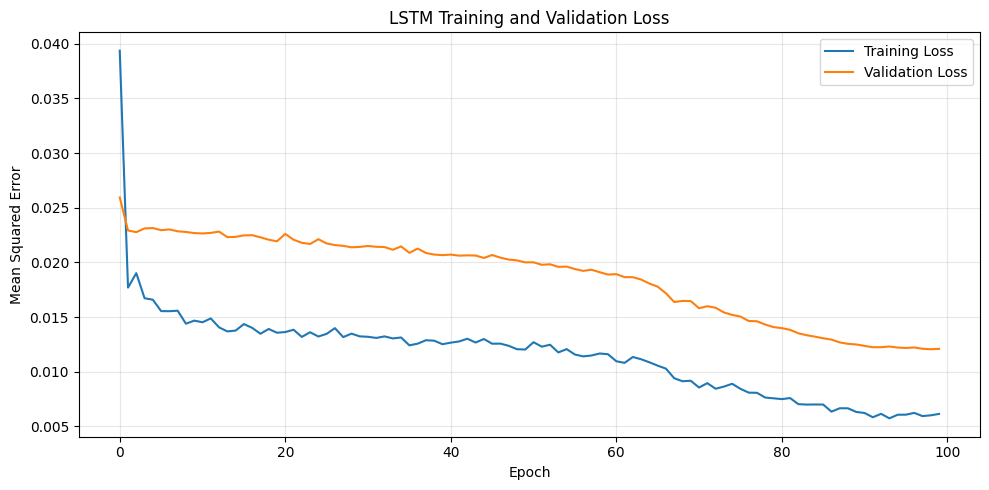

In [23]:
plt.figure(figsize=(10, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("LSTM Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("../outputs/figures/08_lstm_training_validation_loss.png")
plt.show()

In [24]:
from sklearn.metrics import mean_absolute_error, mean_squared_error


class ForecastEvaluator:
    def evaluate(self, actual, predicted, model_name):
        mae = mean_absolute_error(actual, predicted)
        rmse = np.sqrt(mean_squared_error(actual, predicted))

        results = {
            "Model": model_name,
            "MAE": mae,
            "RMSE": rmse
        }

        return results


# Generate LSTM predictions on the held-out test period
scaled_predictions = lstm_model.model.predict(X_test_lstm, verbose=0)

lstm_predictions = sequence_preprocessor.scaler.inverse_transform(
    scaled_predictions
).ravel()

# Convert the scaled test targets back to sales values
actual_sales = sequence_preprocessor.scaler.inverse_transform(
    y_test.reshape(-1, 1)
).ravel()

# Compare the baseline and LSTM
evaluator = ForecastEvaluator()

baseline_results = evaluator.evaluate(
    test_df["daily_sales"].to_numpy(),
    baseline_predictions,
    "Naive Baseline"
)

lstm_results = evaluator.evaluate(
    actual_sales,
    lstm_predictions,
    "LSTM"
)

results_df = pd.DataFrame([baseline_results, lstm_results])
results_df

,Model,MAE,RMSE
0,Naive Baseline,165347.387891,227751.165761
1,LSTM,93248.462714,148042.643258


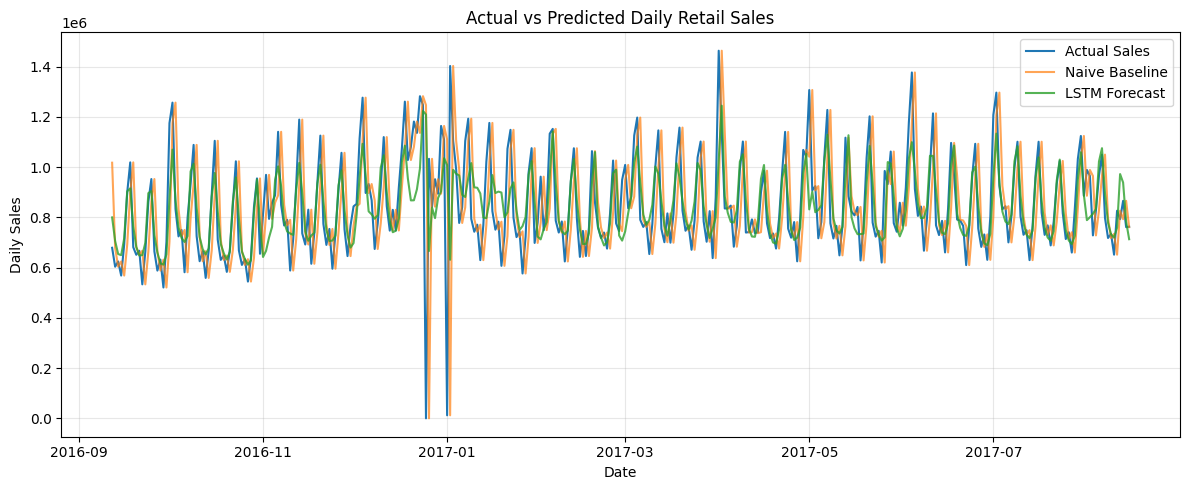

In [25]:
plt.figure(figsize=(12, 5))

plt.plot(test_df["date"], actual_sales, label="Actual Sales")
plt.plot(test_df["date"], baseline_predictions, label="Naive Baseline", alpha=0.7)
plt.plot(test_df["date"], lstm_predictions, label="LSTM Forecast", alpha=0.8)

plt.title("Actual vs Predicted Daily Retail Sales")
plt.xlabel("Date")
plt.ylabel("Daily Sales")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig("../outputs/figures/09_actual_vs_predicted_sales.png")
plt.show()